In [ ]:
# DAY 17 — Create 8–10 Strong Visualizations

Don't make 50 random charts.

Create a focused dashboard/story.

For example:

### 1. Monthly revenue

### 2. Monthly orders

### 3. Top 10 product categories

### 4. Revenue by state

### 5. Payment method distribution

### 6. Review score distribution

### 7. Delivery time distribution

### 8. Delivery time vs review score

### 9. Top sellers

### 10. Revenue/category comparison

Use:

```python
Matplotlib
Seaborn
```

---


In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
folder_path = "C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data"
data = {}
for file in os.listdir(folder_path):
    # print(file.split(".")[0])
    data[file.split(".")[0].replace("olist_","").replace("_dataset","").replace("order_","")] = folder_path + "/" + file
data

{'customers': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_customers_dataset.csv',
 'geolocation': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_geolocation_dataset.csv',
 'orders': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_orders_dataset.csv',
 'items': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_order_items_dataset.csv',
 'payments': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_order_payments_dataset.csv',
 'reviews': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_order_reviews_dataset.csv',
 'products': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_products_dataset.csv',
 'sellers': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/olist_sellers_dataset.csv',
 'product_category_name_translation': 'C:/Users/nagal/OneDrive/Documents/Learn/Repo/Olist-Project/data/product_category_name_transla

In [328]:
### 1. Monthly revenue
df_items = pd.read_csv(data["items"])
df_orders = pd.read_csv(data["orders"])

# converting order_purchase_timestamp to datetime
df_orders["order_purchase_timestamp"] = pd.to_datetime(df_orders["order_purchase_timestamp"])
# extracting year and month
df_orders["year"] = df_orders["order_purchase_timestamp"].dt.year
df_orders["month"] = df_orders["order_purchase_timestamp"].dt.month
#calculating revenue per each order
order_revenue = df_items.groupby("order_id")["price"].sum().reset_index(name="revenue")
#Merging revenue with orders table using order_id
revenue_data = pd.merge(
     df_orders[["order_id","year","month"]],
     order_revenue,
     on="order_id",
     how="inner"
)
# calculating monthly data
monthly_revenue = revenue_data.groupby(["year","month"])["revenue"].sum().reset_index()
monthly_revenue.dtypes



year         int32
month        int32
revenue    float64
dtype: object

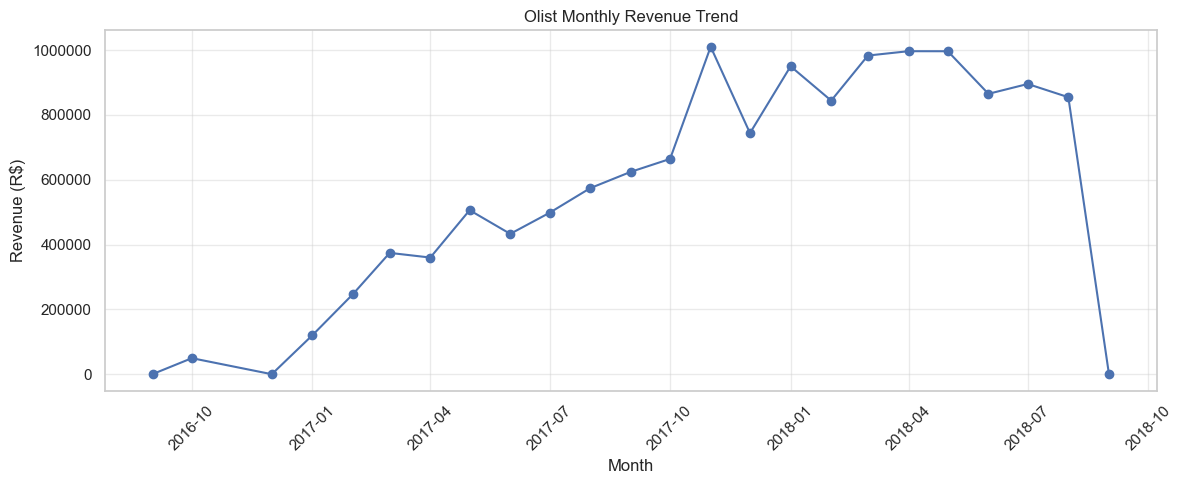

In [329]:

# Create a monthly date for the x-axis
monthly_revenue["month_date"] = pd.to_datetime(
    monthly_revenue["year"].astype(str)
    + "-"
    + monthly_revenue["month"].astype(str)
    + "-01"
)

# Sort by date
monthly_revenue = monthly_revenue.sort_values("month_date")

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["month_date"],
    monthly_revenue["revenue"],
    marker="o"
)

plt.title("Olist Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


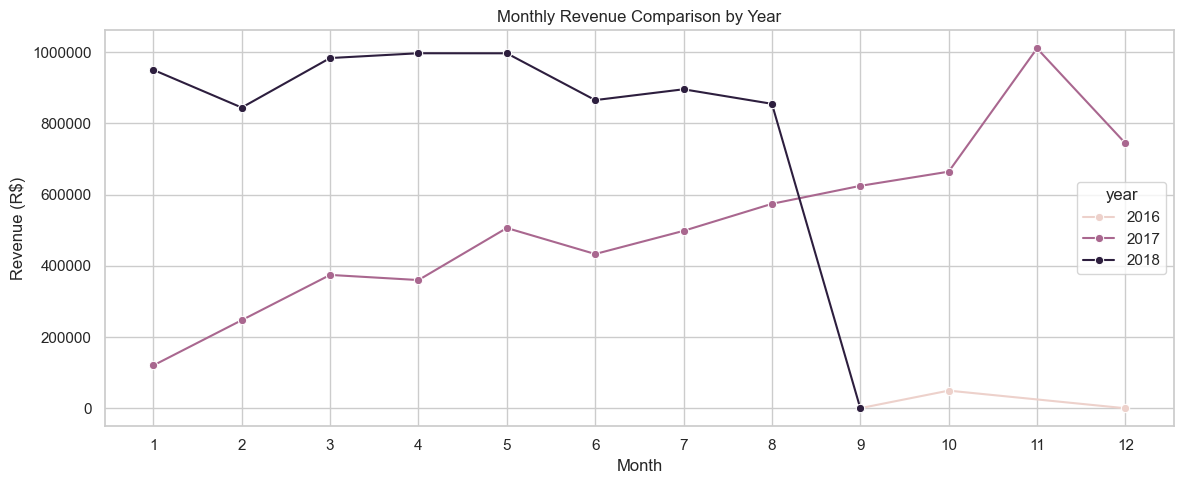

In [330]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="revenue",
    hue="year",
    marker="o"
)

plt.title("Monthly Revenue Comparison by Year")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


In [323]:
# 1.Which month had the highest revenue?
# in november,2017


# 2.What revenue trend did you observe from January to May?

# graduaaly increasing through november 2017,slowly drops on december,again its increased through august 2018 then suddenly drops too much

# 3.Why should we be careful when comparing 2016, 2017, and 2018?
# in 2016 we have 3 months of data
# 2017 full year revenue we have
# 2018 we have 8 months of data


# What recommendation would you give the business based on the revenue trend?

In [331]:
monthly_comparison = monthly_orders.merge(
    monthly_revenue,
    on="month_date",
    how="inner"
)

monthly_comparison

,year_x,month_x,order_count,month_date,year_y,month_y,revenue
0,2016,9,4,2016-09-01,2016,9,267.36
1,2016,10,324,2016-10-01,2016,10,49507.66
2,2016,12,1,2016-12-01,2016,12,10.90
3,2017,1,800,2017-01-01,2017,1,120312.87
4,2017,2,1780,2017-02-01,2017,2,247303.02
5,2017,3,2682,2017-03-01,2017,3,374344.30
6,2017,4,2404,2017-04-01,2017,4,359927.23
7,2017,5,3700,2017-05-01,2017,5,506071.14
8,2017,6,3245,2017-06-01,2017,6,433038.60
9,2017,7,4026,2017-07-01,2017,7,498031.48


In [ ]:
Which month had the highest number of orders?

in novenber 2017 the total number of orders are 7544. this month has highest number of oders. 

How did the number of orders change over time?

gradually increasing through october 2017 in november very high number of orders has placed.
    then gradually decreased through 2018 august then suddenly dropped to very low.

Did the number of orders increase or decrease along with revenue?



What business recommendation can we make based on the trend?

In [326]:
df_orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,9.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2.0


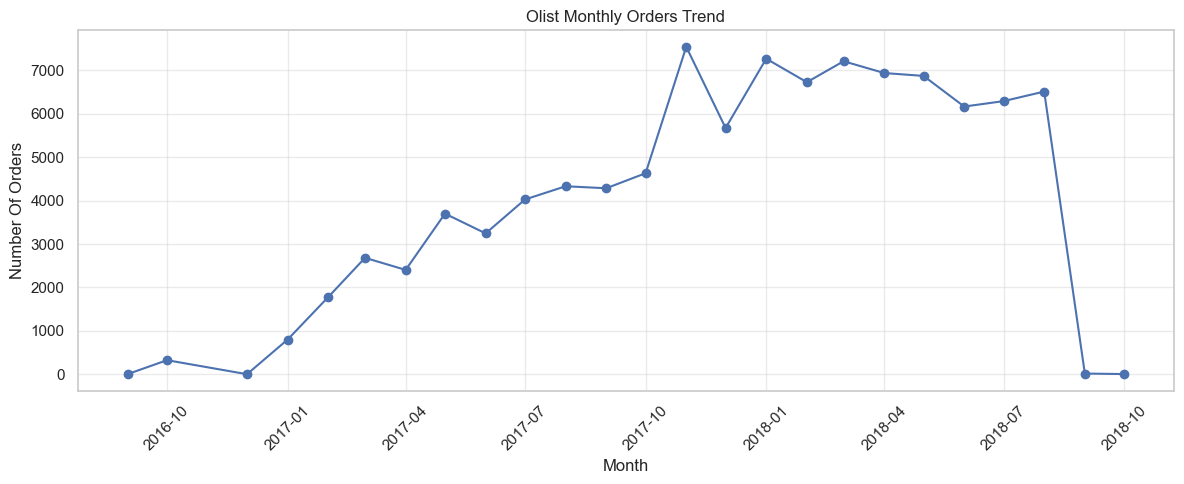

In [327]:
### 2. Monthly orders
df_orders["year"] = df_orders["order_purchase_timestamp"].dt.year
df_orders["month"] = df_orders["order_purchase_timestamp"].dt.month

monthly_orders = df_orders.groupby(
    ["year", "month"]
)["order_id"].count().reset_index(name="order_count")

monthly_orders["month_date"] = pd.to_datetime(
    monthly_orders["year"].astype(str)
    + "-"
    + monthly_orders["month"].astype(str)
    + "-01"
)

monthly_orders = monthly_orders.sort_values("month_date")


plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders["month_date"],
    monthly_orders["order_count"],
    marker="o"
)

plt.title("Olist Monthly Orders Trend")
plt.xlabel("Month")
plt.ylabel("Number Of Orders")
plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


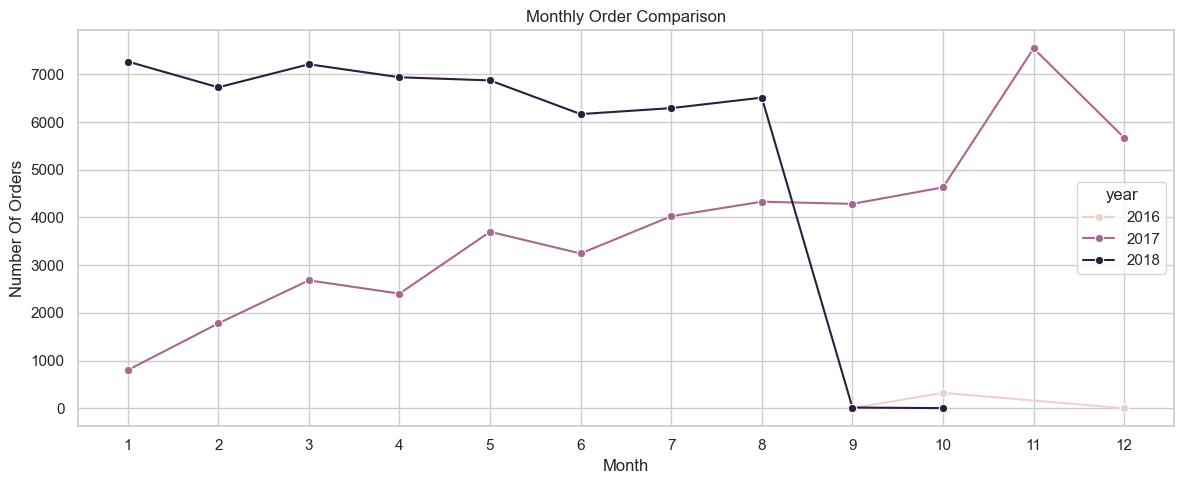

In [27]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_orders,
    x="month",
    y="order_count",
    hue="year",
    marker="o"
)

plt.title("Monthly Order Comparison")
plt.xlabel("Month")
plt.ylabel("Number Of Orders")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


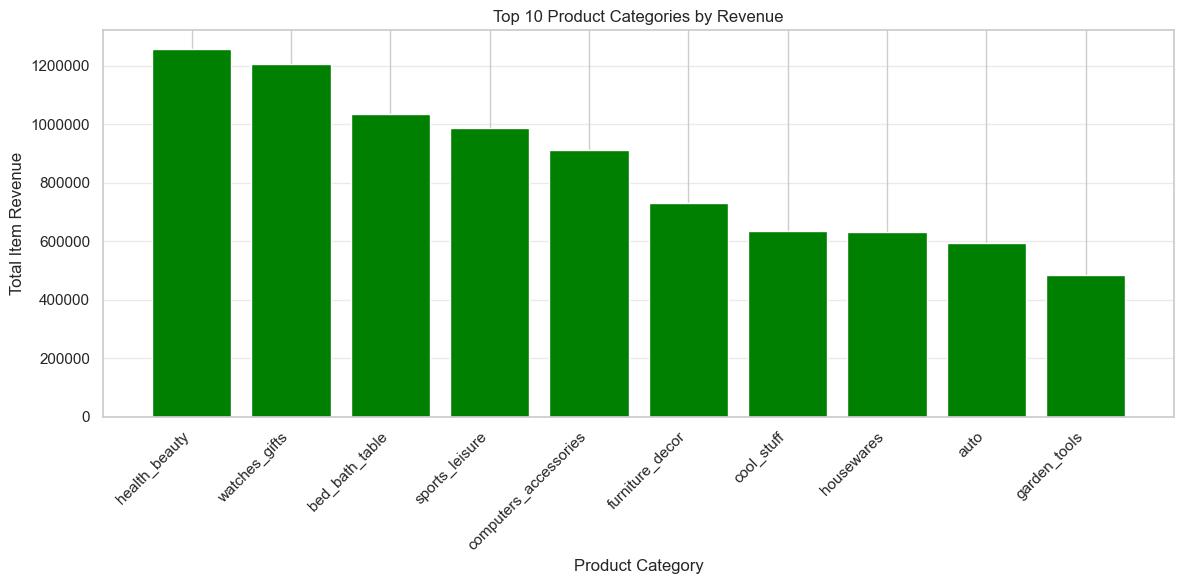

In [332]:

### 3. Top 10 product categories

df_products = pd.read_csv(data["products"])
df_items = pd.read_csv(data["items"])
items_grouped = df_items.groupby(["order_id","product_id"])["price"].sum().reset_index()
products_items = pd.merge(items_grouped,df_products,on="product_id",how="left")
products_items["product_category_name"] = products_items["product_category_name"].fillna("unknown")
Top_10_categories = products_items.groupby("product_category_name")["price"].sum().sort_values(ascending=False).head(10).reset_index()
df_product_category_name_translation = pd.read_csv(data["product_category_name_translation"])  
Top_10_categories = pd.merge(Top_10_categories,df_product_category_name_translation,on="product_category_name",how="left")
Top_10_categories


plt.figure(figsize=(12, 6))
plt.bar(
    Top_10_categories["product_category_name_english"],
    Top_10_categories["price"],
    color="green"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Total Item Revenue")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


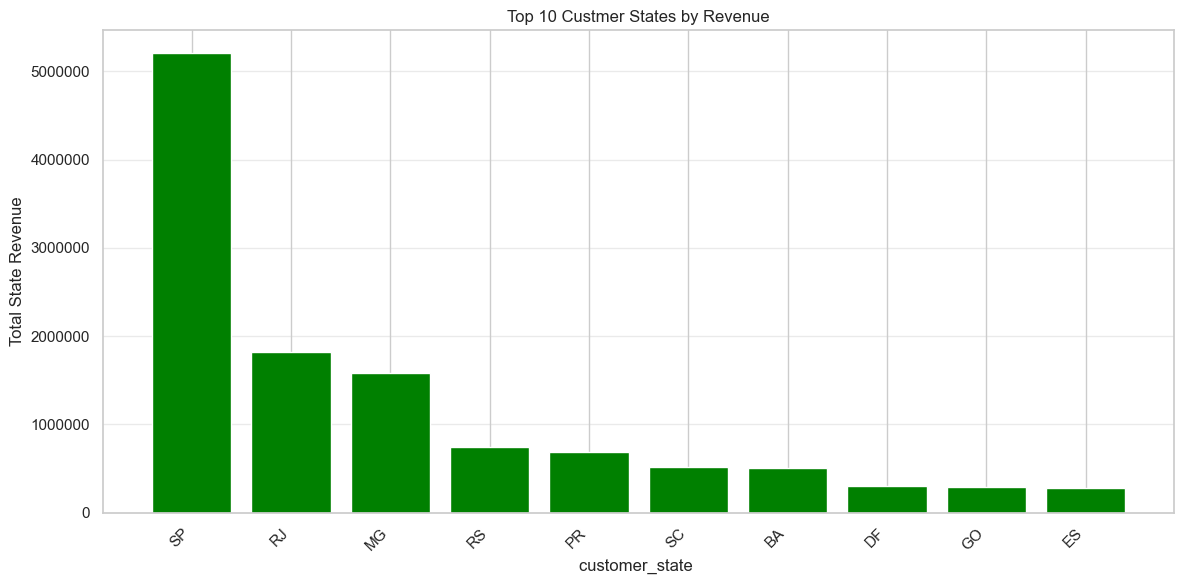

In [334]:
### 4. Revenue by state

df_customers = pd.read_csv(data["customers"])

customers_orders = pd.merge(df_customers,df_orders,on="customer_id",how="left")
df_items = df_items.groupby("order_id")["price"].sum().reset_index()

customers_items = pd.merge(customers_orders,df_items,on="order_id",how="left")

Revenue_state = customers_items.groupby("customer_state")["price"].sum().sort_values(ascending=False).reset_index().head(10)
Revenue_state


plt.figure(figsize=(12, 6))
plt.bar(
    Revenue_state["customer_state"],
    Revenue_state["price"],
    color="green"
)

plt.title("Top 10 Custmer States by Revenue")
plt.xlabel("customer_state ")
plt.ylabel("Total State Revenue")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


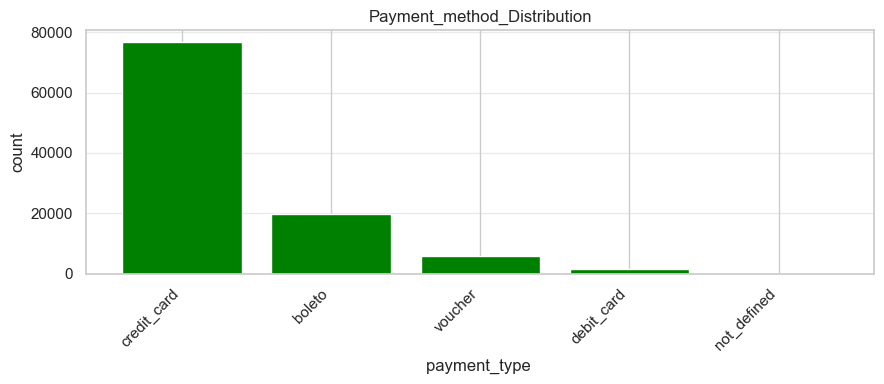

In [335]:
### 5. Payment method distribution

df_payments = pd.read_csv(data["payments"])
payment_method = df_payments["payment_type"].value_counts().reset_index()
payment_method

plt.figure(figsize=(9,4))
plt.bar(
    payment_method["payment_type"],
    payment_method["count"],
    color="green"
)

plt.title("Payment_method_Distribution")
plt.xlabel("payment_type ")
plt.ylabel("count")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


In [336]:
df_payments.groupby("payment_type")["order_id"].nunique()

payment_type
boleto         19784
credit_card    76505
debit_card      1528
not_defined        3
voucher         3866
Name: order_id, dtype: int64

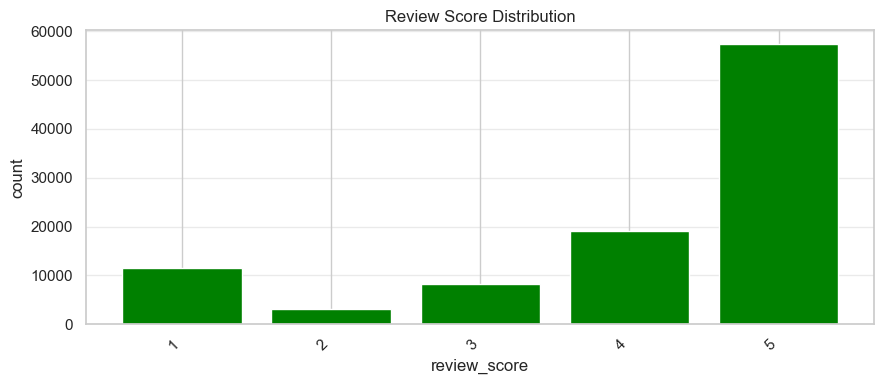

In [337]:
### 6. Review score distribution

df_reviews = pd.read_csv(data["reviews"])
review_score_distribution = df_reviews["review_score"].value_counts().sort_index().reset_index()
plt.figure(figsize=(9,4))
plt.bar(
    review_score_distribution["review_score"],
    review_score_distribution["count"],
    color="green"
)

plt.title("Review Score Distribution")
plt.xlabel("review_score")
plt.ylabel("count")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


In [338]:
review_score_distribution

,review_score,count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


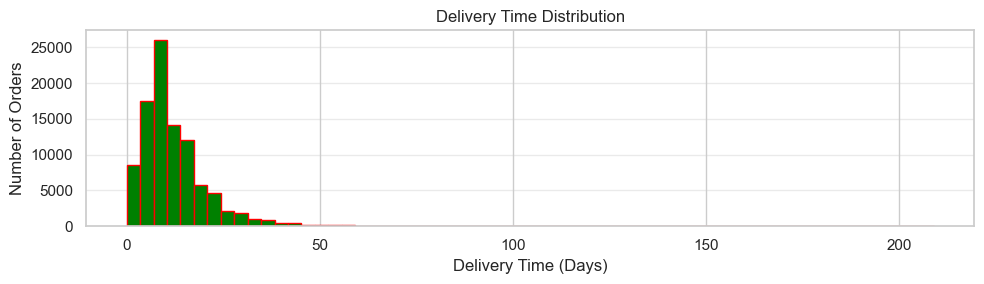

In [339]:
### 7. Delivery time distribution

df_orders["order_delivered_customer_date"] = pd.to_datetime(df_orders["order_delivered_customer_date"])
df_orders["delivery_days"] = (df_orders["order_delivered_customer_date"] - df_orders["order_purchase_timestamp"]).dt.days
df_orders["delivery_days"].describe()


plt.figure(figsize=(10, 3))
plt.hist(
    df_orders["delivery_days"].dropna(),
    bins=60,
    color="green",
    edgecolor="red"
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


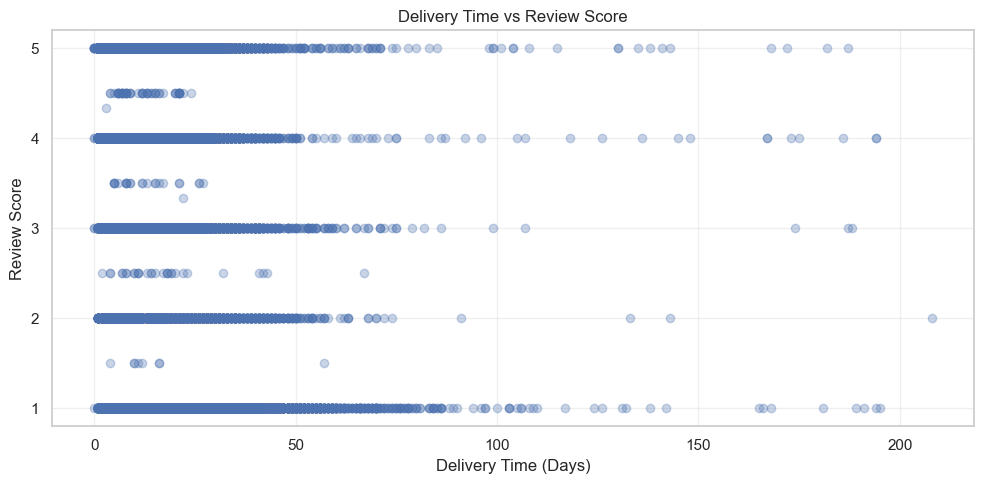

In [340]:
### 8. Delivery time vs review score

df_reviews = pd.read_csv(data["reviews"])
df_reviews = df_reviews.groupby("order_id")["review_score"].mean().reset_index()
reviews_orders = pd.merge(df_reviews,df_orders,on="order_id",how="left")
reviews_orders["review_score"].corr(
reviews_orders["delivery_days"]
)


plt.figure(figsize=(10, 5))
plt.scatter(
    reviews_orders["delivery_days"],
    reviews_orders["review_score"],
    alpha=0.3
)

plt.title("Delivery Time vs Review Score")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Review Score")
plt.yticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


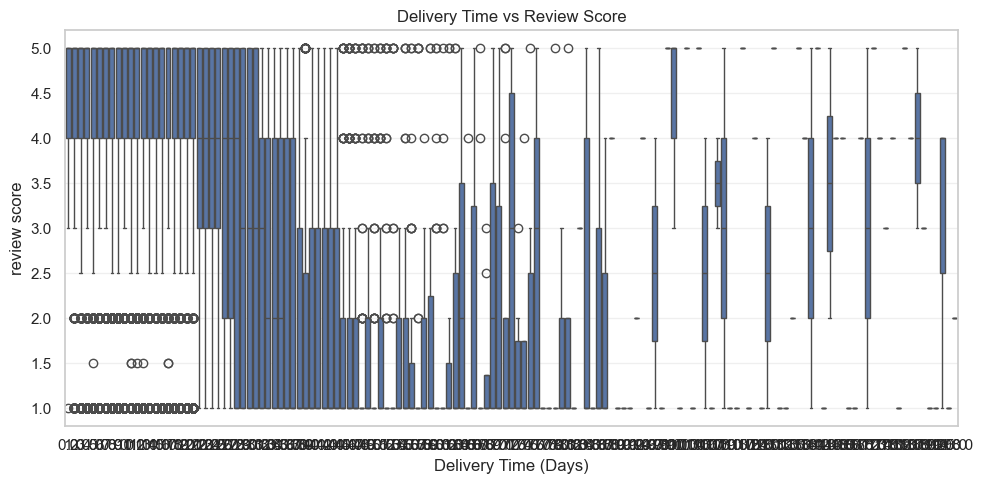

In [311]:
# using box plot
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=reviews_orders,
    x="delivery_days",
    y="review_score"
)

plt.title("Delivery Time vs Review Score")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("review score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

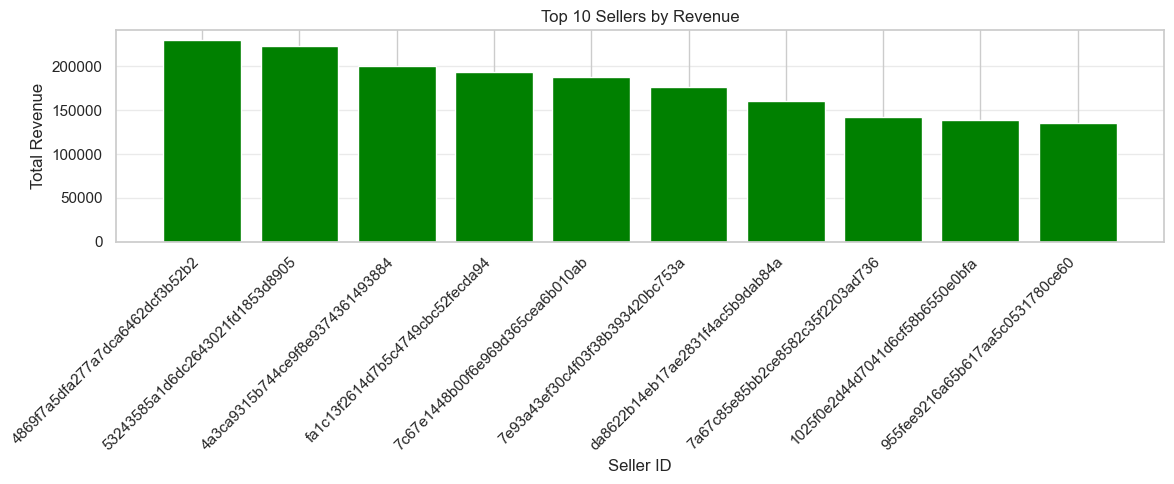

In [236]:
### 9. Top sellers

df_sellers = pd.read_csv(data["sellers"])
df_items = pd.read_csv(data["items"])
top_sellers = df_items.groupby("seller_id")["price"].sum().sort_values(ascending=False).reset_index().head(10)

plt.figure(figsize=(12, 5))
plt.bar(
    top_sellers["seller_id"],
    top_sellers["price"],
    color="green"
)

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Total Revenue")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

In [237]:
df_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [238]:
top_sellers

,seller_id,price
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1,53243585a1d6dc2643021fd1853d8905,222776.05
2,4a3ca9315b744ce9f8e9374361493884,200472.92
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03
4,7c67e1448b00f6e969d365cea6b010ab,187923.89
5,7e93a43ef30c4f03f38b393420bc753a,176431.87
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
9,955fee9216a65b617aa5c0531780ce60,135171.70


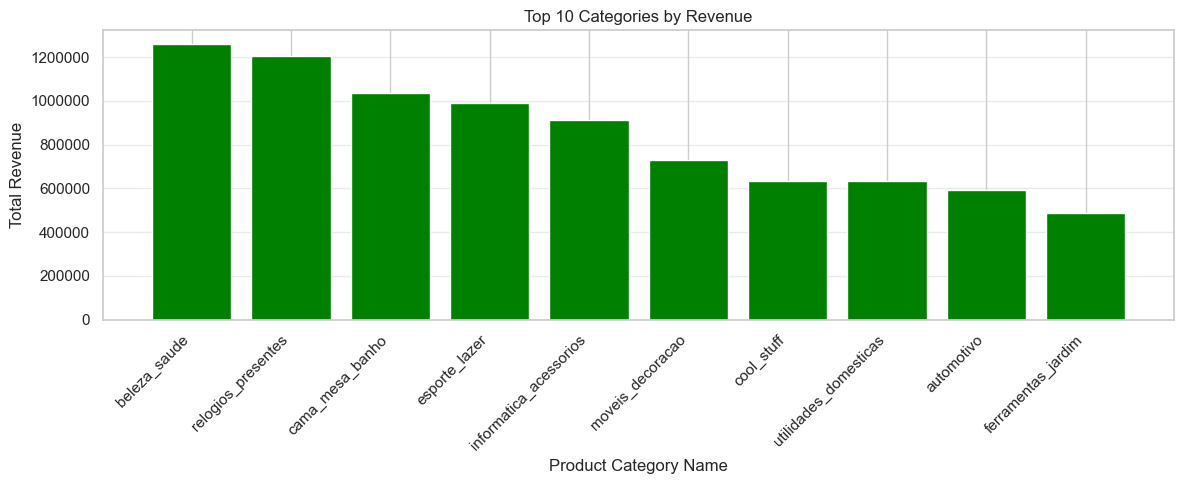

In [301]:
### 10. Revenue/category comparison
df_items = pd.read_csv(data["items"])
items_products = pd.merge(df_items,df_products,on="product_id",how="left")
items_products["product_category_name"] = (
    items_products["product_category_name"].fillna("unknown")
)

top_categories_by_revenue = items_products.groupby("product_category_name")["price"].sum().sort_values(ascending=False).reset_index().head(10)

plt.figure(figsize=(12, 5))
plt.bar(
    top_categories_by_revenue["product_category_name"],
    top_categories_by_revenue["price"],
    color="green"
)

plt.title("Top 10 Categories by Revenue")
plt.xlabel("Product Category Name")
plt.ylabel("Total Revenue")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

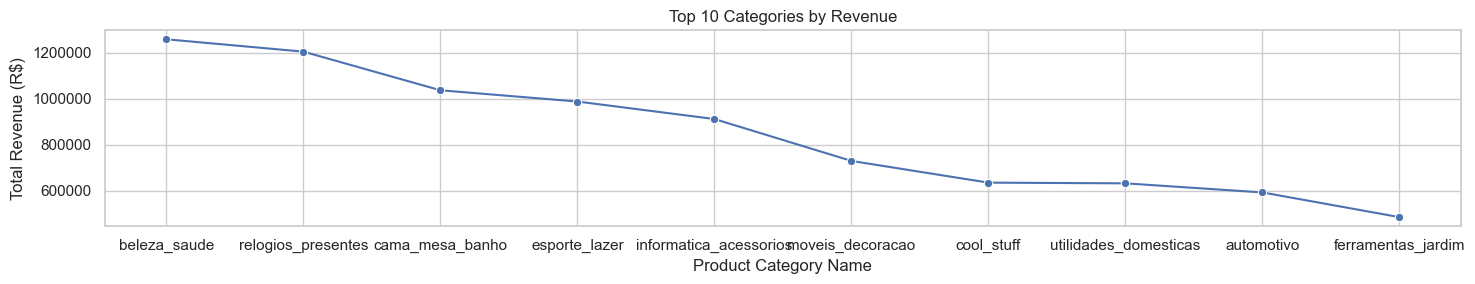

In [306]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(15, 3))

sns.lineplot(
    data=top_categories_by_revenue,
    x="product_category_name",
    y="price",
    marker="o"
)

plt.title("Top 10 Categories by Revenue")
plt.xlabel("Product Category Name")
plt.ylabel("Total Revenue (R$)")
plt.ticklabel_format(axis="y", style="plain")
#plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()
